# **Section 1: SV Data Exploration, Cleaning, and Preprocessing**

#### **Introduction**
The data for this project consists of:
- A Data/svs_core.tsv file generated by the Snakemake pipeline (results/svs_core.tsv). It contains one row per sample and one column per structural variant (SV), with 1 if the SV is present in the sample and 0 if it is absent. SVs were called with Pindel (deletions, tandem duplications and inversions), merged across samples with SURVIVOR, and only **core** SVs were kept: SVs whose locus is covered by reads in at least 95% of the samples (so that absence of the SV is rarely confounded with absence of the region from the genome), and that are present in some but not all samples. In the few samples where a kept SV's locus is not covered, the SV is counted as absent (0). The column frac_samples_covered of the SV information file gives the fraction of samples covering each SV's locus.
- A Data/svs_core_meta.tsv file (results/svs_core_meta.tsv) with information about each SV: its type (DEL, DUP, INV), its length and the number of samples it is present in.
- A ../genome_metadata.csv file with information about the samples (including their resistance profile).

In this notebook, information about the antibiotic we are focusing on, **SXT** is parsed from the metadata file. Each sample is then classified as either *Resistant*, *Susceptible* or *NaN* (not tested) depending on the information in the metadata file. The SV feature matrix is then loaded and preprocessed to ensure that all samples present in the file are classified as either *Resistant* or *Susceptible*. Samples that do not have a resistance profile for SXT are removed from the analysis.

Preliminary data exploration is performed and the data is cleaned to remove errors or empty values.

#### **Contents:**

0. **Helper function**
   - Define a function to parse resistance profiles from the metadata file.


1. **Loading and preprocessing the data**
    - 1.1. Loading the SV feature matrix and SV information
    - 1.2. Loading the metadata
    - 1.3. Cleaning the metadata
    - 1.4. Parsing the resistance profiles
    - 1.5. Filtering by SXT resistance profile


2. **Preliminary data cleaning**
    - 2.1. Removing duplicated samples
    - 2.2. Removing entirely empty rows or columns
    - 2.3. Checking for NaN values
    - 2.4. Checking for data type inconsistencies


3. **Exploratory analysis and visualization**
    - 3.1. SVs per sample
    - 3.2. SVs per feature
    - 3.3. SV types and lengths
    - 3.4. Clustering


4. **Saving the preprocessed data**

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
sns.set_palette('pastel')

# Folders for figures and results
os.makedirs('Figures', exist_ok=True)
os.makedirs('Results', exist_ok=True)

## **0. Helper Function**
We will first write a helper function that will help us parse the resistance profile information present in the metadata file.

The function **parse_resistance_profile** extracts resistance information from genome_metadata.csv. It takes the string present in the *resistance_profile* column of the metadata file as input.

The string containing the resistance information is structured as follows:

"Resistant to SXT; Susceptible to AMC, CAZ; Intermediate to DOX; Not determined: IPM"

To extract the individual resistances, the following steps are performed:

- The string is separated into sections by ";".
- Each section is stripped of whitespaces at the end or the beginning
- The resistance profile is determined by looking at the beginning of the section (Resistant => R, Susceptible => S, Intermediate => I, Not determined => ND)
- The antibiotics corresponding to the resistance profile are saved into a string.
- The antibiotic string is then split according to "," and stripped to remove whitespaces.
- A dictionary entry is created for each antibiotic with the corresponding phenotype

The function then returns the final dictionary with a list of all antibiotics with corresponding phenotypes (R, S, I or ND)

In [2]:
def parse_resistance_profile(resistance_string):
    """
    Parses resistance profile string into individual resistances.
    Returns a dictionary with antibiotic: phenotype (R, S, I or ND).
    """
    # initialize dictionary
    phenotypes = {}

    # Split input string by ";" to get resistance groups
    resistance_string = str(resistance_string).strip().rstrip(';') #remove ";" at the end and whitespaces
    sections = resistance_string.split(';') # split

    for section in sections:
        section = section.strip() # remove whitespace if present
        antibiotics_str = ''

        # Determine resistance profile
        if section.startswith('Resistant'):
            phenotype = 'R'
            antibiotics_str = section.replace('Resistant to', '').strip()
        elif section.startswith('Susceptible'):
            phenotype = 'S'
            antibiotics_str = section.replace('Susceptible to', '').strip()
        elif section.startswith('Intermediate'):
            phenotype = 'I'
            antibiotics_str = section.replace('Intermediate to', '').strip()
        elif section.startswith('Not determined'):
            phenotype = 'ND'
            antibiotics_str = section.replace('Not determined:', '').strip()

        # Split antibiotics by ","
        antibiotics = [ab.strip() for ab in antibiotics_str.split(',')]

        for antibiotic in antibiotics:
            if antibiotic:
                phenotypes[antibiotic] = phenotype

    return phenotypes

## **1. Loading and Preprocessing the data**
We will start by loading the SV feature matrix and the sample metadata. We will then make sure that all samples in the feature matrix have a corresponding resistance profile for the antibiotic **SXT**.

### **1.1 Loading the SV feature matrix and SV information**

In [3]:
# Load the SV presence/absence matrix (samples x SVs)
sv_matrix = pd.read_csv('Data/svs_core.tsv', sep='\t', index_col=0)

print(f'Shape: {sv_matrix.shape}')
print(f'Data types: {sv_matrix.dtypes.unique()}')
print(f'Missing values: {sv_matrix.isna().sum().sum()} / {sv_matrix.size} ({100*sv_matrix.isna().sum().sum()/sv_matrix.size:.2f}%)')

Shape: (227, 3501)
Data types: [dtype('int64')]
Missing values: 0 / 794727 (0.00%)


In [4]:
# Load the SV information (type, length, number of samples carrying the SV)
sv_meta = pd.read_csv('Data/svs_core_meta.tsv', sep='\t', index_col=0)

print(f'Shape: {sv_meta.shape}')
print(sv_meta.head())

Shape: (3501, 3)
                                svtype  svlen  n_present
sv_id                                                   
sv__NZ_CP009156.1_1254_1350_DEL    DEL     96         12
sv__NZ_CP009156.1_1327_1431_DEL    DEL    104         60
sv__NZ_CP009156.1_1891_1956_INV    INV     65         24
sv__NZ_CP009156.1_3595_3673_DEL    DEL     78         15
sv__NZ_CP009156.1_5152_5252_DEL    DEL    100         51


### **1.2 Loading the metadata**

In [5]:
# Load metadata with resistance profiles
metadata = pd.read_csv('../genome_metadata.csv')

print(f'Shape: {metadata.shape}')
print(f'\nColumns: {metadata.columns}')
print(f'\n')
print(metadata.head())

Shape: (265, 8)

Columns: Index(['sra_accession', 'genome_name', 'source', 'species', 'ST', 'location',
       'resistance_profile', 'status'],
      dtype='str')


  sra_accession genome_name   source          species    ST  \
0    SRR2102060  SRR2102060  Patient  B. pseudomallei   NaN   
1    SRR2975745  SRR2975745  Patient  B. pseudomallei   NaN   
2    SRR6075117    MSHR0647  Patient  B. pseudomallei   NaN   
3    SRR9598635  SRR9598635  Patient  B. pseudomallei   NaN   
4   SRR27387687     EPAC065  Patient  B. pseudomallei  1051   

                 location                                 resistance_profile  \
0                     NaN    Resistant to CAZ, AMC; Not determined: SXT, MEM   
1                     NaN    Resistant to CAZ; Not determined: SXT, AMC, MEM   
2                     NaN  Susceptible to MEM, AMC; Not determined: SXT, IPM   
3                     NaN    Resistant to CAZ; Not determined: SXT, AMC, MEM   
4  Thailand:Amnat Charoen     Resistant to SXT; Suscepti

### **1.3 Cleaning the metadata**
Let's keep only samples in the metadata that are also in the SV feature matrix. The cleaned metadata is saved in this folder (Data/genome_metadata_cleaned.csv) rather than in the main folder, so that it does not overwrite the file used by the SNP and CNV notebooks.

In [6]:
# Find common samples between SV data and metadata and keep only common samples
metadata.set_index("sra_accession", inplace=True)

# Remove duplicate samples in both dataframes
metadata = metadata.loc[~metadata.index.duplicated()]
sv_matrix = sv_matrix.loc[~sv_matrix.index.duplicated()]

# Find common samples
common_samples = sv_matrix.index.intersection(metadata.index)

# Keep only samples in the metadata file that are in the SV file
metadata = metadata.loc[common_samples]
sv_matrix = sv_matrix.loc[common_samples]

print(f"\nMerged data shape:")
print(f"SVs: {sv_matrix.shape}")
print(f"Metadata: {metadata.shape}")

# Save the cleaned file
metadata.to_csv("Data/genome_metadata_cleaned.csv")


Merged data shape:
SVs: (227, 3501)
Metadata: (227, 7)


### **1.4 Parsing the resistance profiles**
Now that we have loaded and cleaned the metadata, we will extract the resistance profile for each sample using the function parse_resistance_profile defined above.
We will apply the function to each row in the metadata to obtain a dictionary with {antibiotic1: profile1, antibotic2: profile2, etc.} for each sample.

We will then convert the dictionary to a data frame (each column is an antibiotic) and add the sample name as index.

In [7]:
# Parse resistances for each sample: outputs a dictionary with antibiotic : profile pairs for each row (each sample)
parsed_resistances = metadata["resistance_profile"].apply(parse_resistance_profile) # apply the function to each row

# Convert to DataFrame (json_normalize creates one column per entry in the dictionary)
resistances_df = pd.json_normalize(parsed_resistances)

# Add sample name and set it as index
resistances_df['sra_accession'] = metadata.index.values
resistances_df = resistances_df.set_index('sra_accession')

print(f'Resistance profiles shape: {resistances_df.shape}')
print(f'Antibiotics detected: {resistances_df.columns.tolist()}\n')
print(resistances_df.head())

Resistance profiles shape: (227, 5)
Antibiotics detected: ['SXT', 'CAZ', 'MEM', 'AMC', 'IPM']

              SXT  CAZ MEM AMC  IPM
sra_accession                      
SRR3404582      R    S   S   S  NaN
SRR3404597      R    S   S   S  NaN
SRR3404599      R    S   S   S  NaN
SRR5927082      S  NaN   S   S    S
SRR6075123      S  NaN   R   S    S


### **1.5 Filter by SXT resistance profile**
Finally, we will keep only samples that have a valid resistance profile for the antibiotic we are interested in (SXT).

In [8]:
# Extract SXT resistance profile
SXT_profile = resistances_df['SXT']

# Keep only samples with valid SXT phenotype (S or R)
valid_samples = SXT_profile.isin(['S', 'R'])
sv_matrix = sv_matrix.loc[valid_samples]
SXT_profile = SXT_profile.loc[valid_samples]

# Convert to binary (0=Susceptible, 1=Resistant)
SXT_profile = (SXT_profile == 'R').astype(int)

print(f'Valid samples: {len(sv_matrix)}')
print(f'\nSXT resistance distribution:')
print(SXT_profile.value_counts())

Valid samples: 227

SXT resistance distribution:
SXT
1    123
0    104
Name: count, dtype: int64


## **2. Preliminary data cleaning**
We will now perform some simple data cleaning to remove duplicated samples and check for empty values.

### **2.1 Remove duplicated samples**
Duplicated sample names were already removed in section 1.3. Unlike for the SNPs, I do **not** remove samples that have an identical SV profile: there are far fewer SV features than SNP features, so two different strains can genuinely carry exactly the same set of SVs (for instance strains with no SV at all). Removing them would remove real samples. Let's just count how many samples share their SV profile with another sample.

In [9]:
# Samples whose SV profile is identical to the profile of another sample
identical_profiles = sv_matrix.duplicated(keep=False)

print(f'Duplicated sample names: {sv_matrix.index.duplicated().sum()}')
print(f'Samples sharing their SV profile with at least one other sample: {identical_profiles.sum()}')
print(f'Number of distinct SV profiles: {len(sv_matrix.drop_duplicates())}')

Duplicated sample names: 0
Samples sharing their SV profile with at least one other sample: 2


Number of distinct SV profiles: 226


### **2.2 Remove entirely empty rows / columns**
Let's now see if any rows or columns are entirely empty, and if yes, let's remove them.

In [10]:
print("our data set contains", sv_matrix.isna().all(axis=1).sum(), "empty rows")
print("our data set contains", sv_matrix.isna().all(axis=0).sum(), "empty columns")

our data set contains 0 empty rows


our data set contains 0 empty columns


### **2.3 Adressing NaN values**
Let's see if there are any individual missing values. The pipeline only keeps SVs with a complete genotype in every sample, so there shouldn't be any.

In [11]:
print(f'Number of NaN values: {sv_matrix.isna().sum().sum()} / {sv_matrix.size}')

Number of NaN values: 0 / 794727


### **2.4 Ensuring Data Type consistency**
Let's now make sure that all of our data is in the format that we are expecting. The SV data should be binary and equal to 1 if the SV is present or 0 if absent.

In [12]:
print("Data types present in the feature matrix:")
sv_matrix.dtypes.value_counts()

Data types present in the feature matrix:


int64    3501
Name: count, dtype: int64

In [13]:
invalid = (~sv_matrix.isin([0, 1])).sum().sum()
print(f"{invalid} entries are different than 0 or 1")

0 entries are different than 0 or 1


## **3. EDA and visualizations**
Let's now perform some simple data exploration to understand our data better.

### **3.1 SVs per sample**
Let's plot the total number of SVs per sample, as well as the percentage of "1" per sample

In [14]:
counts = sv_matrix.sum(axis=1)
percentage = sv_matrix.mean(axis=1) * 100

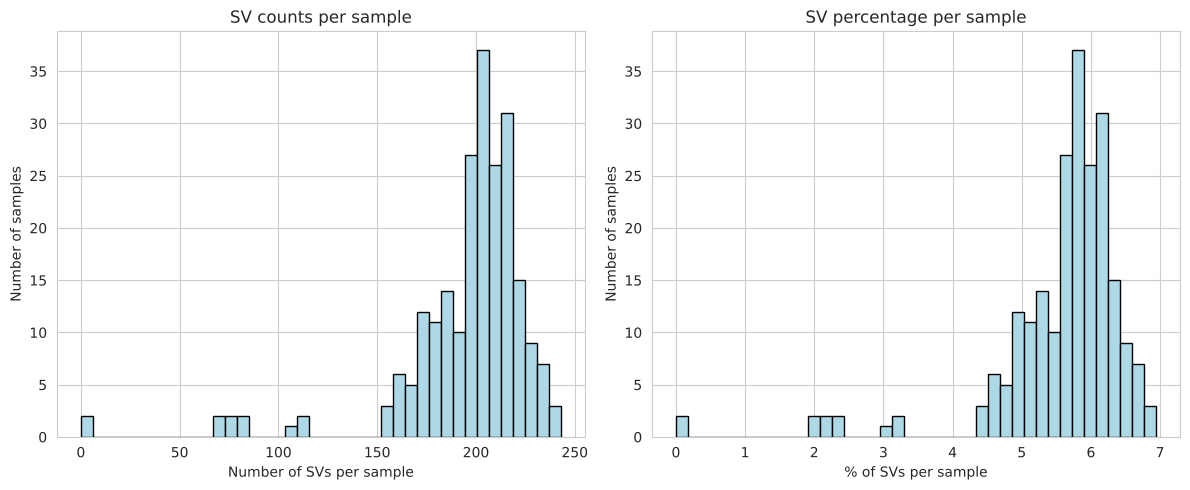

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SVs per sample')
axes[0].set_ylabel('Number of samples')
axes[0].set_title('SV counts per sample')

axes[1].hist(percentage, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SVs per sample')
axes[1].set_ylabel('Number of samples')
axes[1].set_title('SV percentage per sample')

plt.tight_layout()
plt.savefig('Figures/01_SVs_per_sample.png', dpi=300, bbox_inches='tight')
plt.show()

Samples with very few SVs are simply close to the reference strain. Clusters of samples with a similar number of SVs could reflect bacterial lineages (SVs, like SNPs, are inherited together).

### **3.2 SVs per feature**
Let's now visualize in how many samples (and in which percentage of samples) each SV is present.

In [16]:
counts_regions = sv_matrix.sum(axis=0)
percentage_regions = sv_matrix.mean(axis=0) * 100

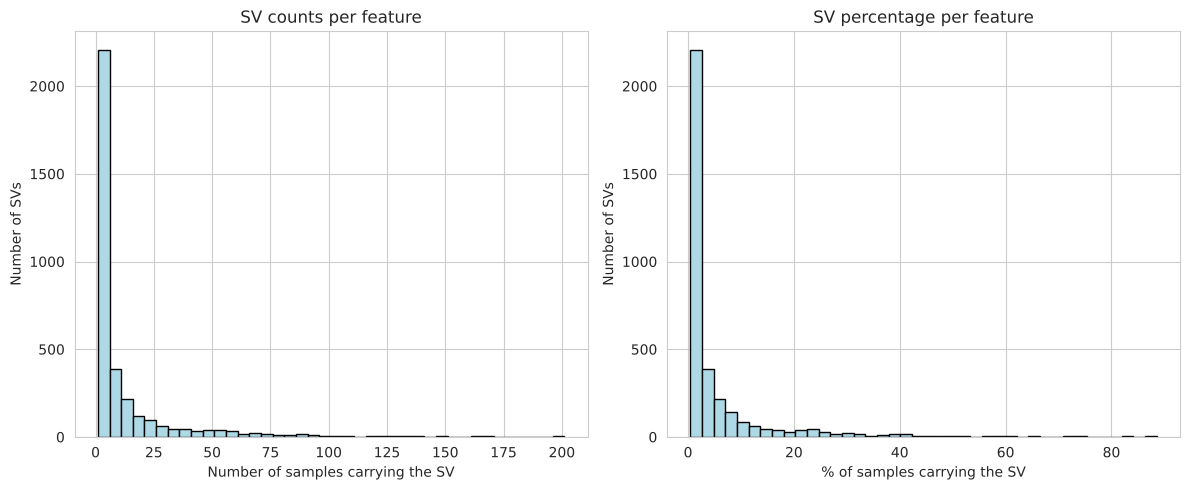

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of samples carrying the SV')
axes[0].set_ylabel('Number of SVs')
axes[0].set_title('SV counts per feature')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of samples carrying the SV')
axes[1].set_ylabel('Number of SVs')
axes[1].set_title('SV percentage per feature')

plt.tight_layout()
plt.savefig('Figures/01_SVs_per_feature.png', dpi=300, bbox_inches='tight')
plt.show()

The pipeline already removed SVs that are present in all samples or in none, but SVs present in only one or a few samples carry very little information for a machine learning model. As for the SNPs, I will remove features with very little variance after splitting the data into training and test sets, using the training data only.

### **3.3 SV types and lengths**
Let's look at the kinds of SVs in the data set, using the SV information file: the number of SVs of each type, their length, and whether resistant and susceptible strains carry different amounts of each type.

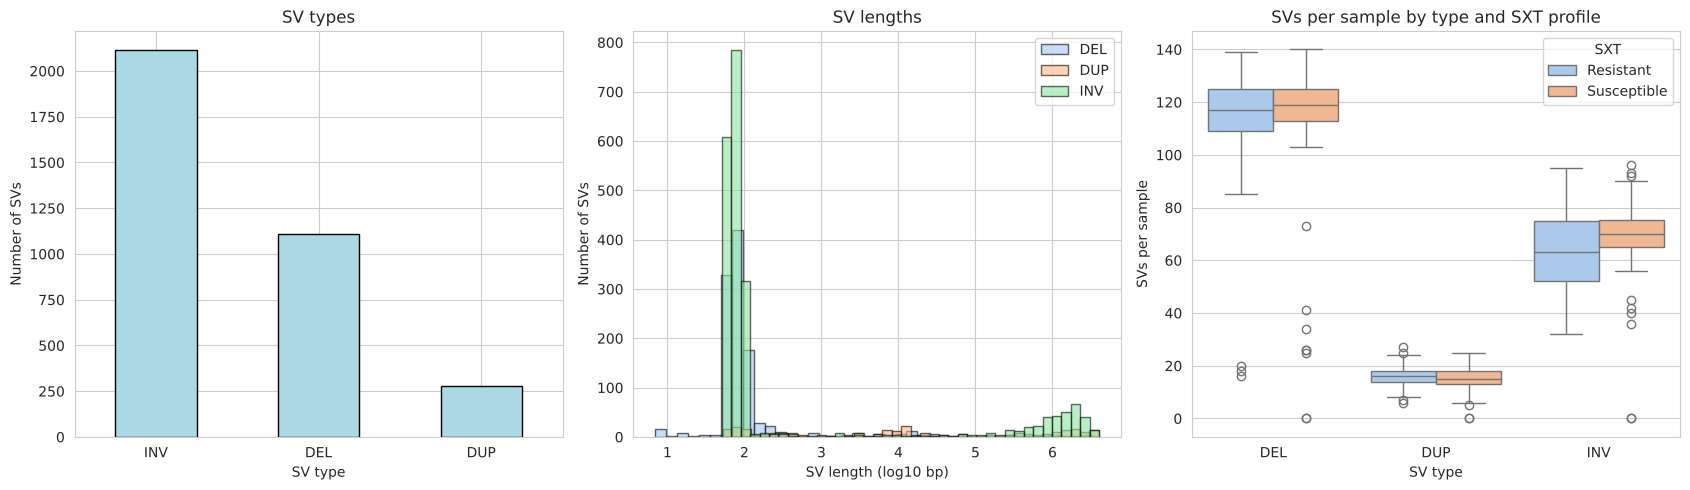

In [18]:
sv_meta = sv_meta.loc[sv_matrix.columns]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Number of SVs of each type
sv_meta['svtype'].value_counts().plot(kind='bar', ax=axes[0], color='lightblue', edgecolor='black')
axes[0].set_xlabel('SV type')
axes[0].set_ylabel('Number of SVs')
axes[0].set_title('SV types')
axes[0].tick_params(axis='x', rotation=0)

# Length distribution per type
for svtype, group in sv_meta.groupby('svtype'):
    axes[1].hist(np.log10(group['svlen'].clip(lower=1)), bins=40, alpha=0.6, label=svtype, edgecolor='black')
axes[1].set_xlabel('SV length (log10 bp)')
axes[1].set_ylabel('Number of SVs')
axes[1].set_title('SV lengths')
axes[1].legend()

# Number of SVs of each type per sample, resistant vs susceptible
per_type = pd.DataFrame({svtype: sv_matrix[ids].sum(axis=1) for svtype, ids in sv_meta.groupby('svtype').groups.items()})
per_type['SXT'] = SXT_profile.map({0: 'Susceptible', 1: 'Resistant'})
per_type_long = per_type.melt(id_vars='SXT', var_name='SV type', value_name='SVs per sample')
sns.boxplot(data=per_type_long, x='SV type', y='SVs per sample', hue='SXT', ax=axes[2])
axes[2].set_title('SVs per sample by type and SXT profile')

plt.tight_layout()
plt.savefig('Figures/01_SV_types_lengths.png', dpi=300, bbox_inches='tight')
plt.show()

### **3.4 Clustering**
Let's see how the samples ressemble each other and if some already cluster together based on their SVs. We can do this by computing a pairwise SV distance matrix (using the Hamming distance between samples). The Hamming distance is the total number of SVs that differ between two samples.
Once we have calculated this, we can cluster and visualize using seaborn's *clustermap* function.

As for the SNPs, this is a quick visualisation: hierarchical agglomerative clustering on the Hamming distance counts every difference the same, and only looks at whether an SV is present or absent. The phylogenetic tree built by the pipeline (IQ-Tree on the core SNP alignment) is a better estimate of the strains' relationships.

In [19]:
X = sv_matrix.values
dist = X @ (1 - X).T + (1 - X) @ X.T
dist_df = pd.DataFrame(dist, index=sv_matrix.index, columns=sv_matrix.index)

In [20]:
Z = linkage(squareform(dist_df.values, checks=False), method="average")

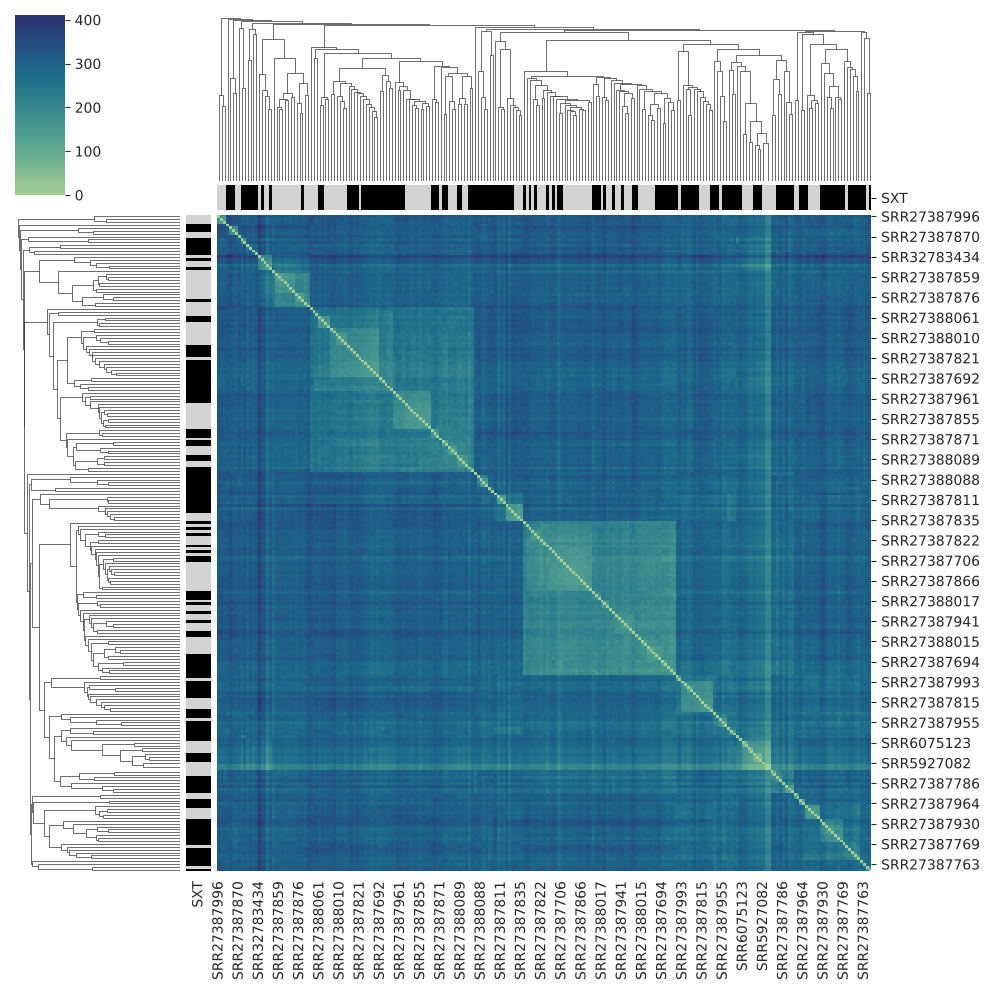

In [21]:
palette = {0: "lightgrey", 1: "black"}
strain_colors = SXT_profile.map(palette).rename("SXT")

sns.clustermap(dist_df, cmap="crest", row_linkage=Z, col_linkage=Z, row_colors=strain_colors, col_colors=strain_colors)

plt.savefig('Figures/01_Clustering.png', dpi=600, bbox_inches='tight')
plt.show()

If resistant (black) and susceptible (grey) strains are spread across the tree rather than forming separate blocks, the model is more likely to learn to predict resistance and not simply lineages.

## **4. Save preprocessed data**
Let's save the preprocessed data.

In [22]:
# Save cleaned SV matrix
sv_matrix.to_csv('Data/sv_cleaned.csv')

# Save SXT resistance profile
SXT_profile.to_csv('Data/SXT_cleaned.csv', header=['SXT_binary'])

print(f'Shape: {sv_matrix.shape}')

Shape: (227, 3501)
